In [1]:
# Import required libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set up plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Load the metadata CSV
df = pd.read_csv('../data/SatTAC_metadata.csv')

# Display basic information about the dataset
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nFirst few rows:")
df.head()

Dataset Shape: (63, 39)

Column Names:
['record_id', 'session', 'timepoint', 'condition', 'lab_session_timepoints_timestamp', 'brac', 'asatq_total', 'asatq_satis', 'asatq_avers', 'asatq_total_redmotiv', 'baes_stim', 'baes_sed', 'seas_hipos', 'seas_hineg', 'seas_lopos', 'seas_loneg', 'auq_total', 'deq_feel', 'deq_like', 'deq_dislike', 'deq_more', 'vas_hungry', 'vas_sat', 'vas_full', 'screening_survey_timestamp', 'bmi', 'audit_total', 'pastmo_wkdd', 'pastmo_min_wkdd', 'pastmo_max_wkdd', 'pastmo_dpdd', 'pastmo_binge_f', 'pastmo_binge_m', 'dob', 'age', 'sex', 'ethnicity', 'race', 'educ']

First few rows:


,record_id,session,timepoint,condition,lab_session_timepoints_timestamp,brac,asatq_total,asatq_satis,asatq_avers,asatq_total_redmotiv,...,pastmo_max_wkdd,pastmo_dpdd,pastmo_binge_f,pastmo_binge_m,dob,age,sex,ethnicity,race,educ
0,145,1,1,alcohol,12/13/24 9:41,0.000,118,40,50,38,...,3,5,NaN,8.0,5/28/83,41,0,1,6,7
1,145,1,2,alcohol,12/13/24 11:03,0.045,41,18,8,15,...,3,5,NaN,8.0,5/28/83,41,0,1,6,7
2,145,1,3,alcohol,12/13/24 11:26,0.048,26,20,5,1,...,3,5,NaN,8.0,5/28/83,41,0,1,6,7
3,145,1,4,alcohol,12/13/24 11:43,0.055,62,26,19,21,...,3,5,NaN,8.0,5/28/83,41,0,1,6,7
4,145,1,5,alcohol,12/13/24 11:55,0.074,48,18,19,13,...,3,5,NaN,8.0,5/28/83,41,0,1,6,7


In [2]:
# Examine data types and missing values
print("Data Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nUnique values in key categorical columns:")
print(f"Record IDs: {df['record_id'].unique()}")
print(f"Sessions: {df['session'].unique()}")
print(f"Timepoints: {df['timepoint'].unique()}")
print(f"Conditions: {df['condition'].unique()}")
print(f"Sex: {df['sex'].unique()}")
print(f"Age range: {df['age'].min()} - {df['age'].max()}")

Data Types:
record_id                             int64
session                               int64
timepoint                             int64
condition                            object
lab_session_timepoints_timestamp     object
brac                                float64
asatq_total                           int64
asatq_satis                           int64
asatq_avers                           int64
asatq_total_redmotiv                  int64
baes_stim                             int64
baes_sed                              int64
seas_hipos                            int64
seas_hineg                            int64
seas_lopos                            int64
seas_loneg                            int64
auq_total                             int64
deq_feel                              int64
deq_like                              int64
deq_dislike                           int64
deq_more                              int64
vas_hungry                            int64
vas_sat             

# 1. Study Design Overview
Let's start with understanding the overall study structure and participant characteristics.

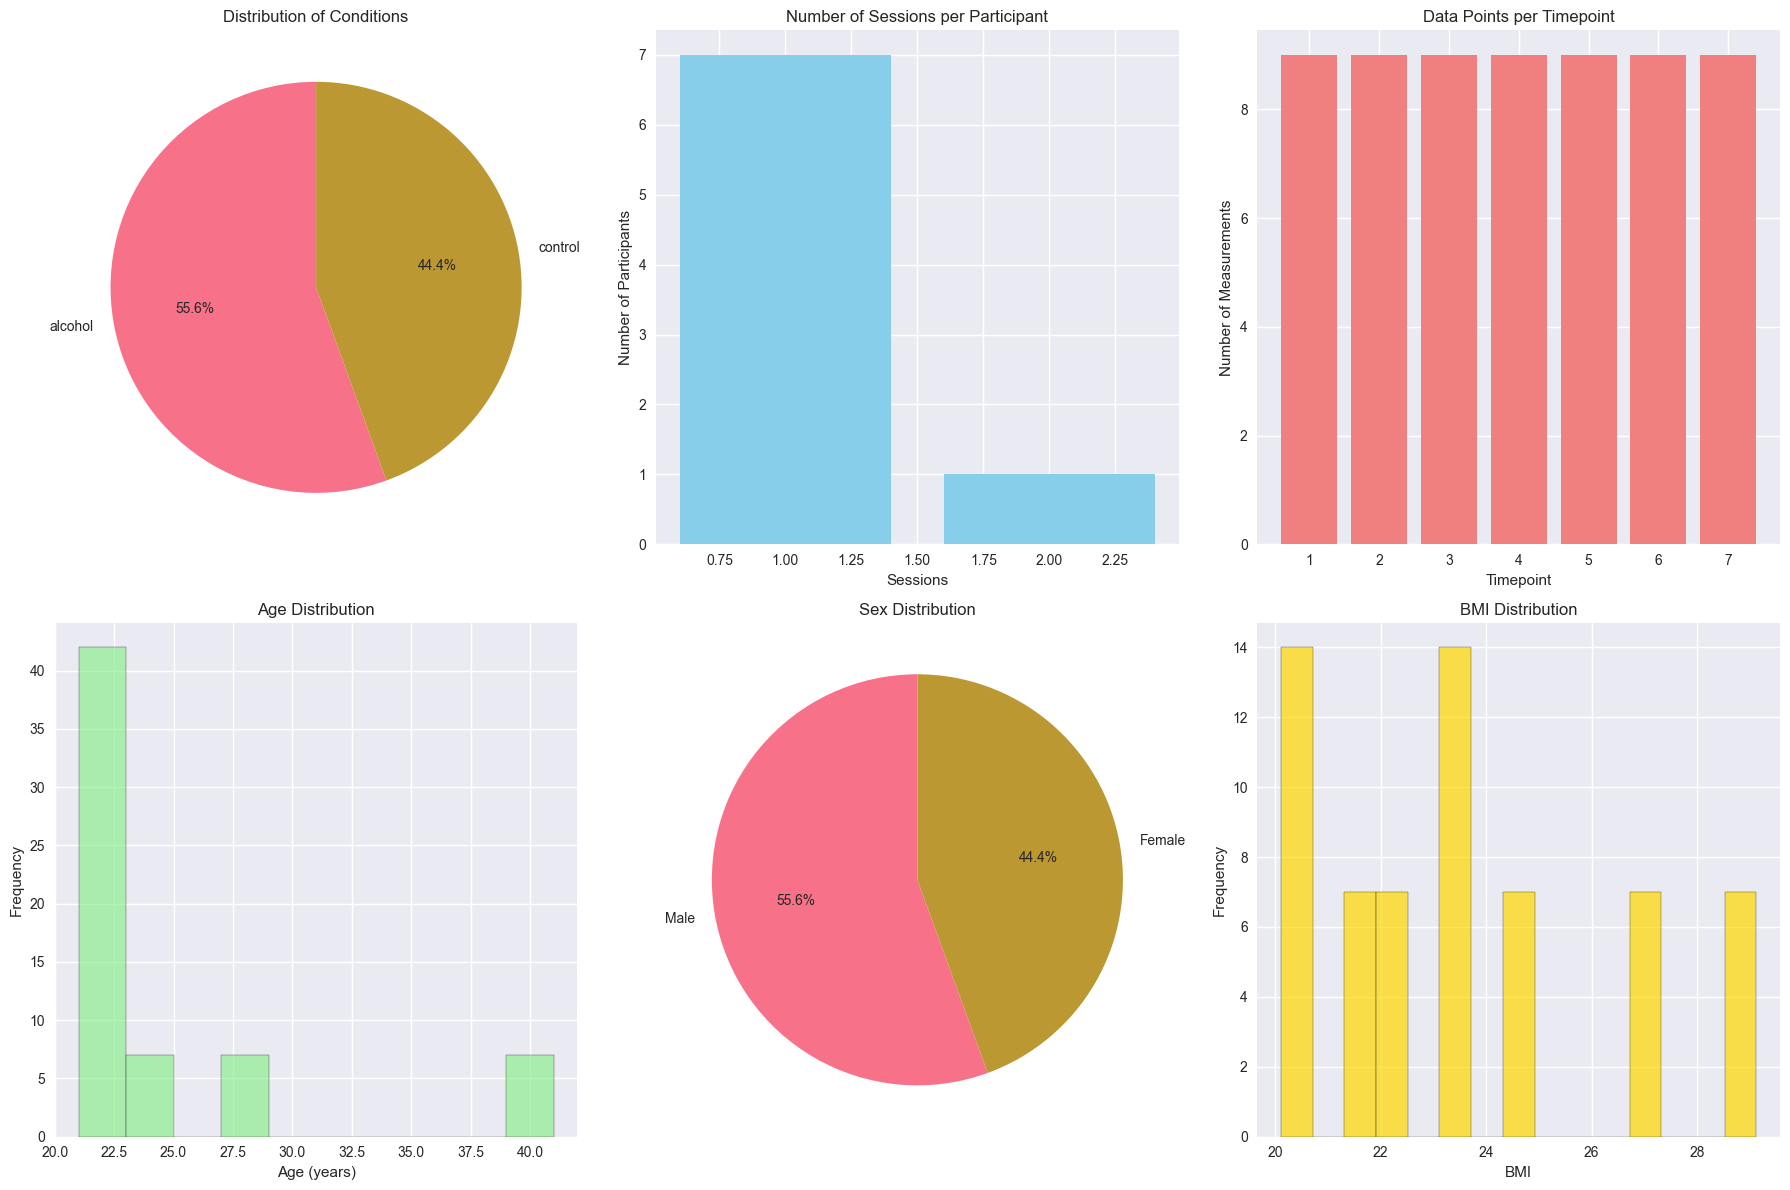

Study Overview:
Total participants: 8
Total measurements: 63
Age: 24.7 ± 6.2 years
BMI: 23.5 ± 2.9
AUDIT total: 11.4 ± 3.4


In [3]:
# Study Design Overview
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Participants per condition
condition_counts = df['condition'].value_counts()
axes[0,0].pie(condition_counts.values, labels=condition_counts.index, autopct='%1.1f%%', startangle=90)
axes[0,0].set_title('Distribution of Conditions')

# 2. Sessions per participant
session_counts = df.groupby('record_id')['session'].nunique().value_counts().sort_index()
axes[0,1].bar(session_counts.index, session_counts.values, color='skyblue')
axes[0,1].set_title('Number of Sessions per Participant')
axes[0,1].set_xlabel('Sessions')
axes[0,1].set_ylabel('Number of Participants')

# 3. Timepoints distribution
timepoint_counts = df['timepoint'].value_counts().sort_index()
axes[0,2].bar(timepoint_counts.index, timepoint_counts.values, color='lightcoral')
axes[0,2].set_title('Data Points per Timepoint')
axes[0,2].set_xlabel('Timepoint')
axes[0,2].set_ylabel('Number of Measurements')

# 4. Age distribution
axes[1,0].hist(df['age'].dropna(), bins=10, color='lightgreen', alpha=0.7, edgecolor='black')
axes[1,0].set_title('Age Distribution')
axes[1,0].set_xlabel('Age (years)')
axes[1,0].set_ylabel('Frequency')

# 5. Sex distribution
sex_counts = df['sex'].value_counts()
sex_labels = ['Female' if x == 0 else 'Male' for x in sex_counts.index]
axes[1,1].pie(sex_counts.values, labels=sex_labels, autopct='%1.1f%%', startangle=90)
axes[1,1].set_title('Sex Distribution')

# 6. BMI distribution
axes[1,2].hist(df['bmi'].dropna(), bins=15, color='gold', alpha=0.7, edgecolor='black')
axes[1,2].set_title('BMI Distribution')
axes[1,2].set_xlabel('BMI')
axes[1,2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Study Overview:")
print(f"Total participants: {df['record_id'].nunique()}")
print(f"Total measurements: {len(df)}")
print(f"Age: {df['age'].mean():.1f} ± {df['age'].std():.1f} years")
print(f"BMI: {df['bmi'].mean():.1f} ± {df['bmi'].std():.1f}")
print(f"AUDIT total: {df['audit_total'].mean():.1f} ± {df['audit_total'].std():.1f}")

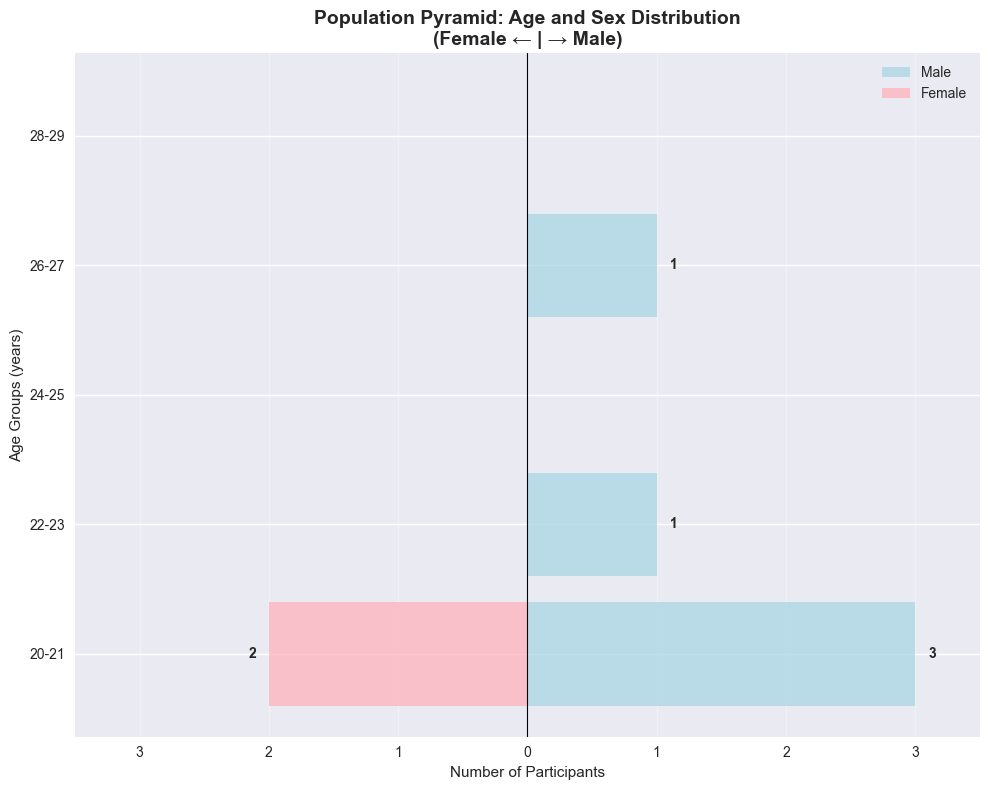

Age and Sex Distribution Summary:
Total participants: 8
Female participants: 3
Male participants: 5
Age range: 21 - 41 years
Mean age: 25.0 ± 6.8 years

Age distribution by sex:
     count  mean   std  min  max
sex                             
0        3  28.0  11.3   21   41
1        5  23.2   2.8   21   28


: 

In [ ]:
# Population Pyramid: Age and Sex Distribution
participant_unique = df.drop_duplicates('record_id')[['age', 'sex']].dropna()

# Create age bins
age_bins = np.arange(20, 32, 2)  # Bins from 20 to 30 in steps of 2
age_labels = [f'{int(age_bins[i])}-{int(age_bins[i+1])-1}' for i in range(len(age_bins)-1)]

# Bin the ages
participant_unique['age_bin'] = pd.cut(participant_unique['age'], bins=age_bins, labels=age_labels, include_lowest=True)

# Count participants by age bin and sex
age_sex_counts = participant_unique.groupby(['age_bin', 'sex']).size().unstack(fill_value=0)

# Create the population pyramid
fig, ax = plt.subplots(figsize=(10, 8))

# Get the age bins for y-axis
y_pos = np.arange(len(age_labels))

# Plot horizontal bars for males (right side, positive values)
males = age_sex_counts.get(1, pd.Series(0, index=age_sex_counts.index))
ax.barh(y_pos, males, height=0.8, label='Male', color='lightblue', alpha=0.8)

# Plot horizontal bars for females (left side, negative values)
females = age_sex_counts.get(0, pd.Series(0, index=age_sex_counts.index))
ax.barh(y_pos, -females, height=0.8, label='Female', color='lightpink', alpha=0.8)

# Customize the plot
ax.set_yticks(y_pos)
ax.set_yticklabels(age_labels)
ax.set_xlabel('Number of Participants')
ax.set_ylabel('Age Groups (years)')
ax.set_title('Population Pyramid: Age and Sex Distribution\n(Female ← | → Male)', fontsize=14, fontweight='bold')

# Add vertical line at x=0
ax.axvline(x=0, color='black', linewidth=0.8)

# Set x-axis to show absolute values
max_count = max(males.max(), females.max())
ax.set_xlim(-max_count-0.5, max_count+0.5)

# Customize x-axis labels to show absolute values
x_ticks = ax.get_xticks()
ax.set_xticklabels([str(abs(int(x))) for x in x_ticks])

# Add legend
ax.legend(loc='upper right')

# Add grid for better readability
ax.grid(True, alpha=0.3, axis='x')

# Add text annotations showing exact counts
for i, (age_group, row) in enumerate(age_sex_counts.iterrows()):
    male_count = row.get(1, 0)
    female_count = row.get(0, 0)
    
    if male_count > 0:
        ax.text(male_count + 0.1, i, str(int(male_count)), 
                va='center', ha='left', fontsize=10, fontweight='bold')
    if female_count > 0:
        ax.text(-female_count - 0.1, i, str(int(female_count)), 
                va='center', ha='right', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary statistics
print("Age and Sex Distribution Summary:")
print(f"Total participants: {len(participant_unique)}")
print(f"Female participants: {(participant_unique['sex'] == 0).sum()}")
print(f"Male participants: {(participant_unique['sex'] == 1).sum()}")
print(f"Age range: {participant_unique['age'].min():.0f} - {participant_unique['age'].max():.0f} years")
print(f"Mean age: {participant_unique['age'].mean():.1f} ± {participant_unique['age'].std():.1f} years")
print("\nAge distribution by sex:")
print(participant_unique.groupby('sex')['age'].agg(['count', 'mean', 'std', 'min', 'max']).round(1))

# 2. Blood Alcohol Content (BRAC) Analysis
The primary physiological measure in this study appears to be BRAC (Blood/Breath Alcohol Content).

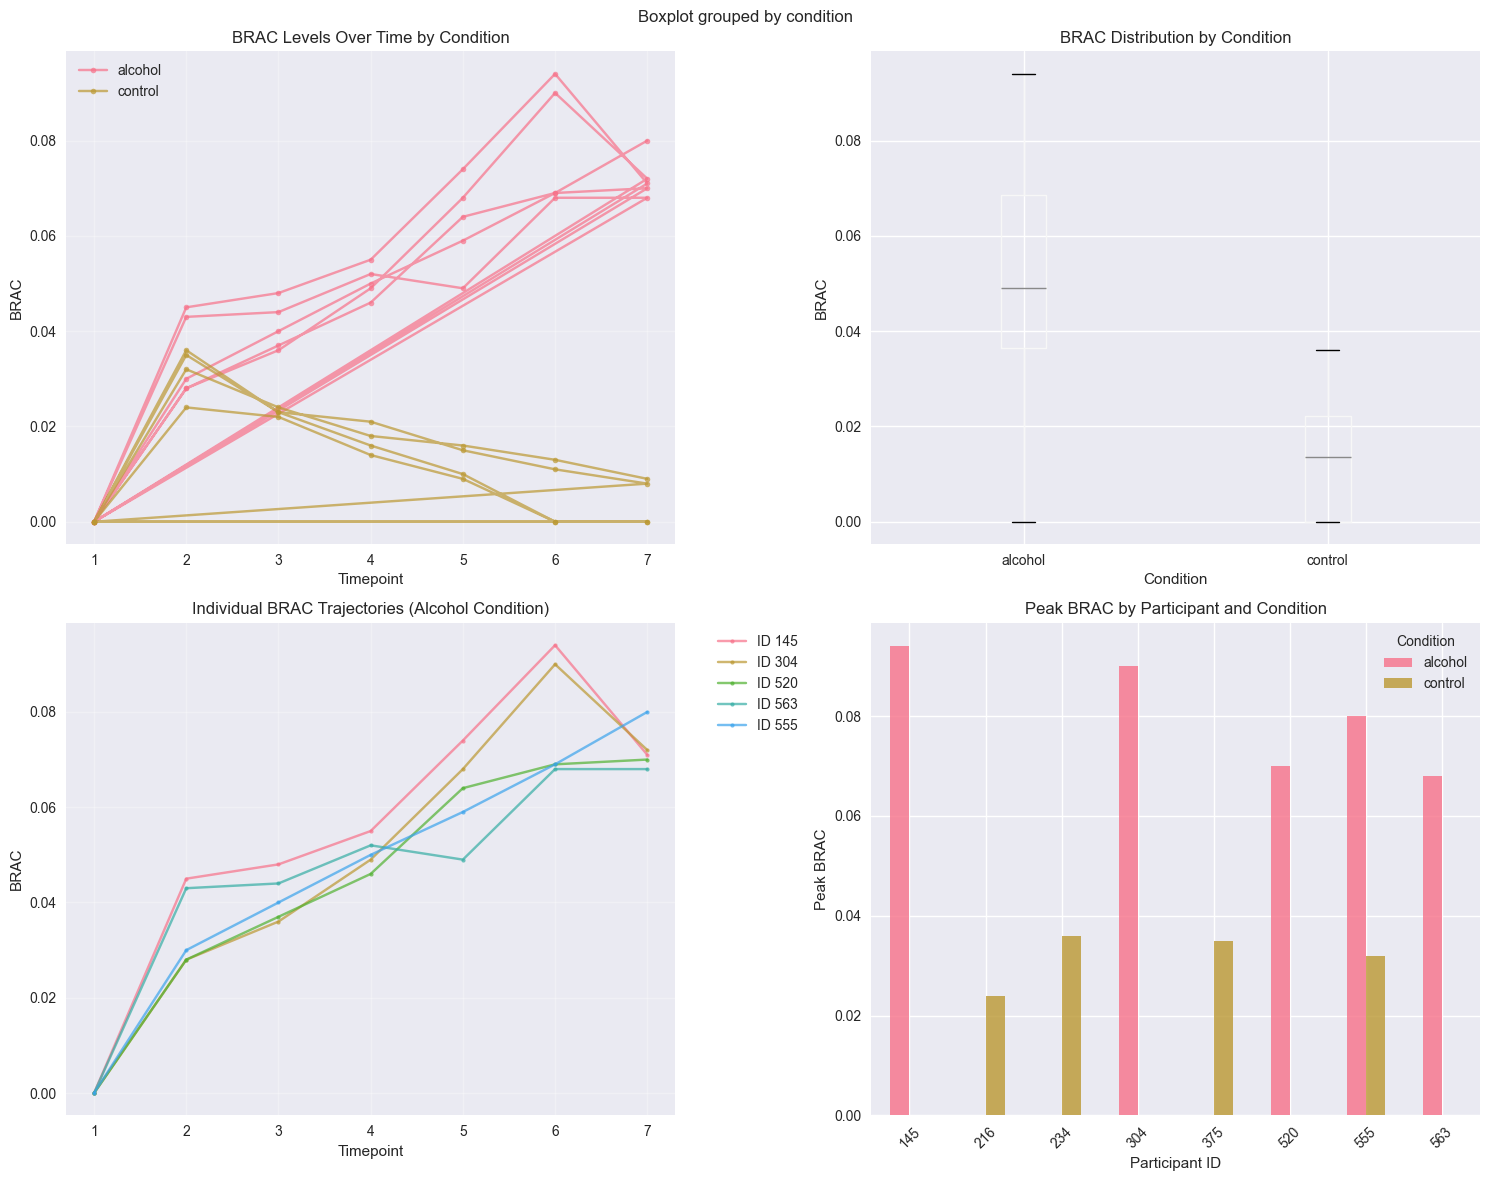

BRAC Statistics by Condition:
           count      mean       std  min     25%     50%      75%    max
condition                                                                
alcohol     35.0  0.048457  0.025849  0.0  0.0365  0.0490  0.06850  0.094
control     28.0  0.013536  0.011260  0.0  0.0000  0.0135  0.02225  0.036


In [4]:
# BRAC Analysis
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. BRAC over time by condition
for condition in df['condition'].unique():
    condition_data = df[df['condition'] == condition]
    axes[0,0].plot(condition_data['timepoint'], condition_data['brac'], 'o-', 
                   label=condition, alpha=0.7, markersize=4)
axes[0,0].set_title('BRAC Levels Over Time by Condition')
axes[0,0].set_xlabel('Timepoint')
axes[0,0].set_ylabel('BRAC')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# 2. BRAC distribution by condition
df.boxplot(column='brac', by='condition', ax=axes[0,1])
axes[0,1].set_title('BRAC Distribution by Condition')
axes[0,1].set_xlabel('Condition')
axes[0,1].set_ylabel('BRAC')

# 3. Individual participant BRAC trajectories (alcohol condition only)
alcohol_data = df[df['condition'] == 'alcohol']
for participant in alcohol_data['record_id'].unique():
    participant_data = alcohol_data[alcohol_data['record_id'] == participant]
    axes[1,0].plot(participant_data['timepoint'], participant_data['brac'], 
                   'o-', alpha=0.7, label=f'ID {participant}', markersize=3)
axes[1,0].set_title('Individual BRAC Trajectories (Alcohol Condition)')
axes[1,0].set_xlabel('Timepoint')
axes[1,0].set_ylabel('BRAC')
axes[1,0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1,0].grid(True, alpha=0.3)

# 4. Peak BRAC by participant
peak_brac = df.groupby(['record_id', 'condition'])['brac'].max().reset_index()
peak_brac_pivot = peak_brac.pivot(index='record_id', columns='condition', values='brac').fillna(0)
peak_brac_pivot.plot(kind='bar', ax=axes[1,1], alpha=0.8)
axes[1,1].set_title('Peak BRAC by Participant and Condition')
axes[1,1].set_xlabel('Participant ID')
axes[1,1].set_ylabel('Peak BRAC')
axes[1,1].legend(title='Condition')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# BRAC statistics
print("BRAC Statistics by Condition:")
print(df.groupby('condition')['brac'].describe())

# 3. Psychological and Subjective Measures
The dataset contains multiple psychological scales and subjective measures.

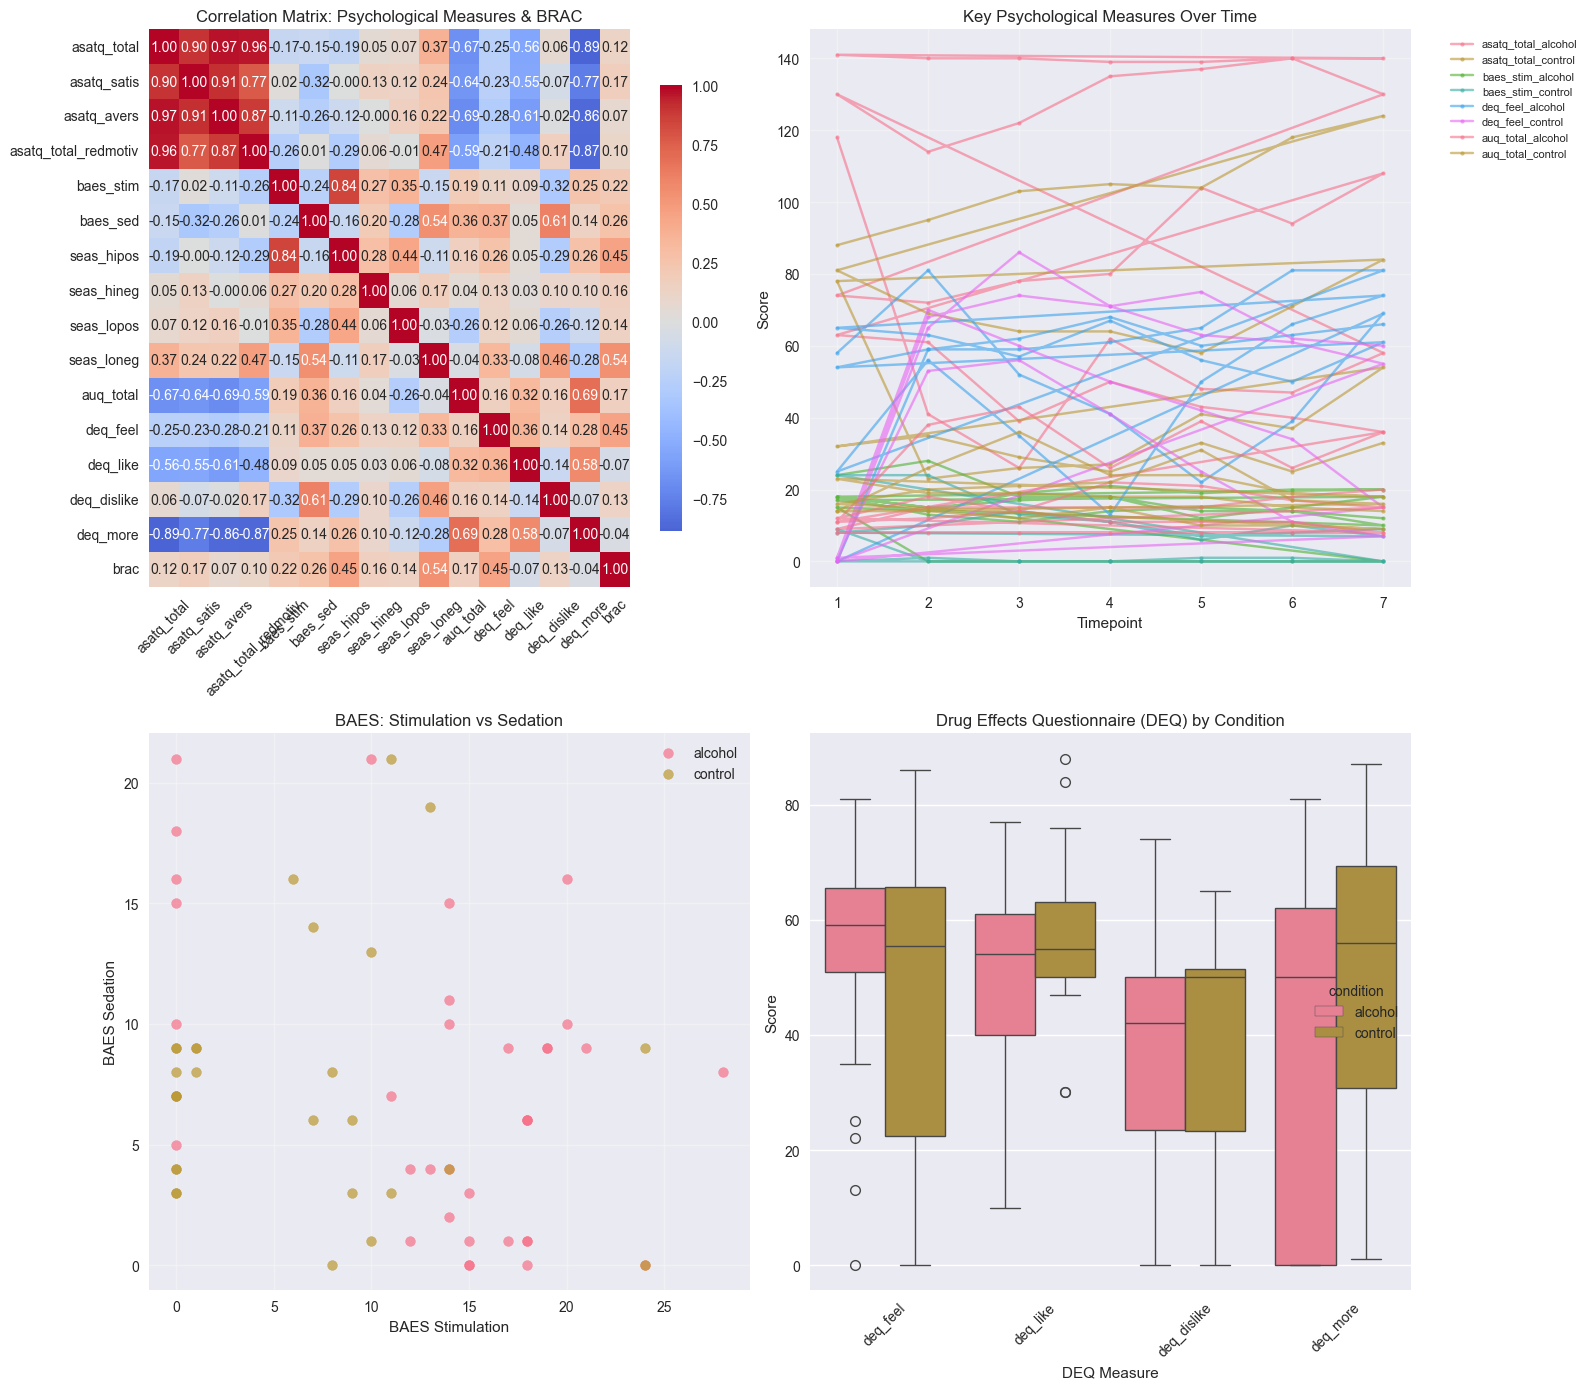

Psychological Measures - Mean ± SD by Condition:

asatq_total:
            mean    std
condition              
alcohol    92.26  40.66
control    61.64  31.97

baes_stim:
            mean   std
condition             
alcohol    13.74  7.26
control     6.21  6.95

deq_feel:
            mean    std
condition              
alcohol    55.37  18.28
control    45.61  27.16

auq_total:
            mean   std
condition             
alcohol    16.54  9.62
control    18.36  6.14


In [5]:
# Psychological and Subjective Measures Analysis
psychological_measures = [
    'asatq_total', 'asatq_satis', 'asatq_avers', 'asatq_total_redmotiv',
    'baes_stim', 'baes_sed', 'seas_hipos', 'seas_hineg', 'seas_lopos', 'seas_loneg',
    'auq_total', 'deq_feel', 'deq_like', 'deq_dislike', 'deq_more'
]

# Create correlation matrix for psychological measures
psych_data = df[psychological_measures + ['brac', 'condition']].copy()

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# 1. Correlation matrix
corr_matrix = psych_data[psychological_measures + ['brac']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, 
            fmt='.2f', ax=axes[0,0], cbar_kws={'shrink': 0.8})
axes[0,0].set_title('Correlation Matrix: Psychological Measures & BRAC')
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].tick_params(axis='y', rotation=0)

# 2. Key measures over time by condition
key_measures = ['asatq_total', 'baes_stim', 'deq_feel', 'auq_total']
for i, measure in enumerate(key_measures):
    for condition in df['condition'].unique():
        condition_data = df[df['condition'] == condition]
        axes[0,1].plot(condition_data['timepoint'], condition_data[measure], 
                      'o-', alpha=0.6, label=f'{measure}_{condition}', markersize=3)
axes[0,1].set_title('Key Psychological Measures Over Time')
axes[0,1].set_xlabel('Timepoint')
axes[0,1].set_ylabel('Score')
axes[0,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[0,1].grid(True, alpha=0.3)

# 3. BAES Stimulation vs Sedation
for condition in df['condition'].unique():
    condition_data = df[df['condition'] == condition]
    axes[1,0].scatter(condition_data['baes_stim'], condition_data['baes_sed'], 
                     alpha=0.7, label=condition, s=50)
axes[1,0].set_title('BAES: Stimulation vs Sedation')
axes[1,0].set_xlabel('BAES Stimulation')
axes[1,0].set_ylabel('BAES Sedation')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# 4. DEQ measures distribution by condition
deq_measures = ['deq_feel', 'deq_like', 'deq_dislike', 'deq_more']
deq_data = df[deq_measures + ['condition']].melt(id_vars=['condition'], 
                                                var_name='DEQ_measure', 
                                                value_name='score')
sns.boxplot(data=deq_data, x='DEQ_measure', y='score', hue='condition', ax=axes[1,1])
axes[1,1].set_title('Drug Effects Questionnaire (DEQ) by Condition')
axes[1,1].set_xlabel('DEQ Measure')
axes[1,1].set_ylabel('Score')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Print psychological measure statistics
print("Psychological Measures - Mean ± SD by Condition:")
for measure in key_measures:
    print(f"\n{measure}:")
    print(df.groupby('condition')[measure].agg(['mean', 'std']).round(2))

# 4. Appetite and Satiety Measures (VAS Scales)
Visual Analog Scale measures for hunger, satiation, and fullness.

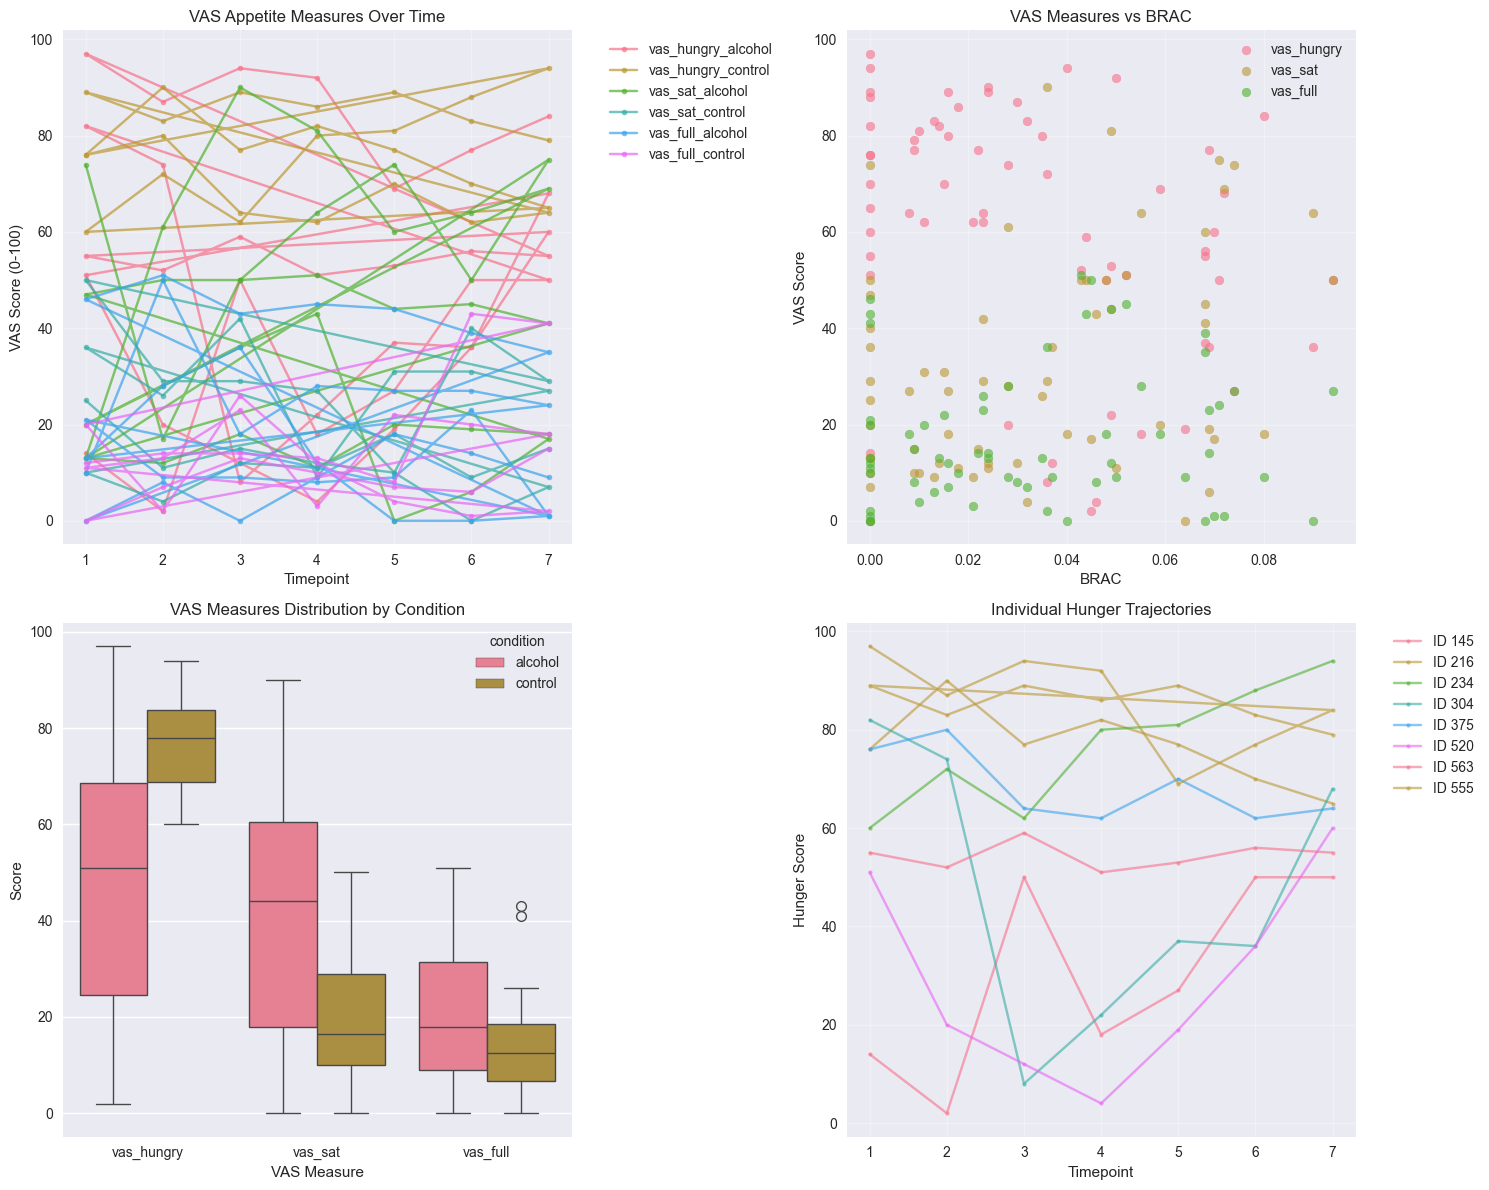

VAS Measures Statistics by Condition:

vas_hungry:
            mean    std  min  max
condition                        
alcohol    49.17  27.33    2   97
control    76.79  10.18   60   94

vas_sat:
            mean    std  min  max
condition                        
alcohol    40.89  24.50    0   90
control    20.54  12.75    0   50

vas_full:
            mean    std  min  max
condition                        
alcohol    20.43  16.11    0   51
control    13.57  10.63    0   43


In [6]:
# VAS (Visual Analog Scale) Analysis for Appetite
vas_measures = ['vas_hungry', 'vas_sat', 'vas_full']

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. VAS measures over time by condition
for measure in vas_measures:
    for condition in df['condition'].unique():
        condition_data = df[df['condition'] == condition]
        axes[0,0].plot(condition_data['timepoint'], condition_data[measure], 
                      'o-', alpha=0.7, label=f'{measure}_{condition}', markersize=4)
axes[0,0].set_title('VAS Appetite Measures Over Time')
axes[0,0].set_xlabel('Timepoint')
axes[0,0].set_ylabel('VAS Score (0-100)')
axes[0,0].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
axes[0,0].grid(True, alpha=0.3)

# 2. VAS correlation with BRAC
for measure in vas_measures:
    axes[0,1].scatter(df['brac'], df[measure], alpha=0.6, label=measure, s=40)
axes[0,1].set_title('VAS Measures vs BRAC')
axes[0,1].set_xlabel('BRAC')
axes[0,1].set_ylabel('VAS Score')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# 3. VAS measures by condition (boxplot)
vas_data = df[vas_measures + ['condition']].melt(id_vars=['condition'], 
                                                var_name='VAS_measure', 
                                                value_name='score')
sns.boxplot(data=vas_data, x='VAS_measure', y='score', hue='condition', ax=axes[1,0])
axes[1,0].set_title('VAS Measures Distribution by Condition')
axes[1,0].set_xlabel('VAS Measure')
axes[1,0].set_ylabel('Score')

# 4. Individual participant VAS trajectories
for participant in df['record_id'].unique():
    participant_data = df[df['record_id'] == participant]
    axes[1,1].plot(participant_data['timepoint'], participant_data['vas_hungry'], 
                   'o-', alpha=0.6, label=f'ID {participant}', markersize=3)
axes[1,1].set_title('Individual Hunger Trajectories')
axes[1,1].set_xlabel('Timepoint')
axes[1,1].set_ylabel('Hunger Score')
axes[1,1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# VAS statistics
print("VAS Measures Statistics by Condition:")
for measure in vas_measures:
    print(f"\n{measure}:")
    print(df.groupby('condition')[measure].agg(['mean', 'std', 'min', 'max']).round(2))

# 5. Drinking Behavior and Baseline Characteristics
Analysis of baseline drinking patterns and demographic factors.

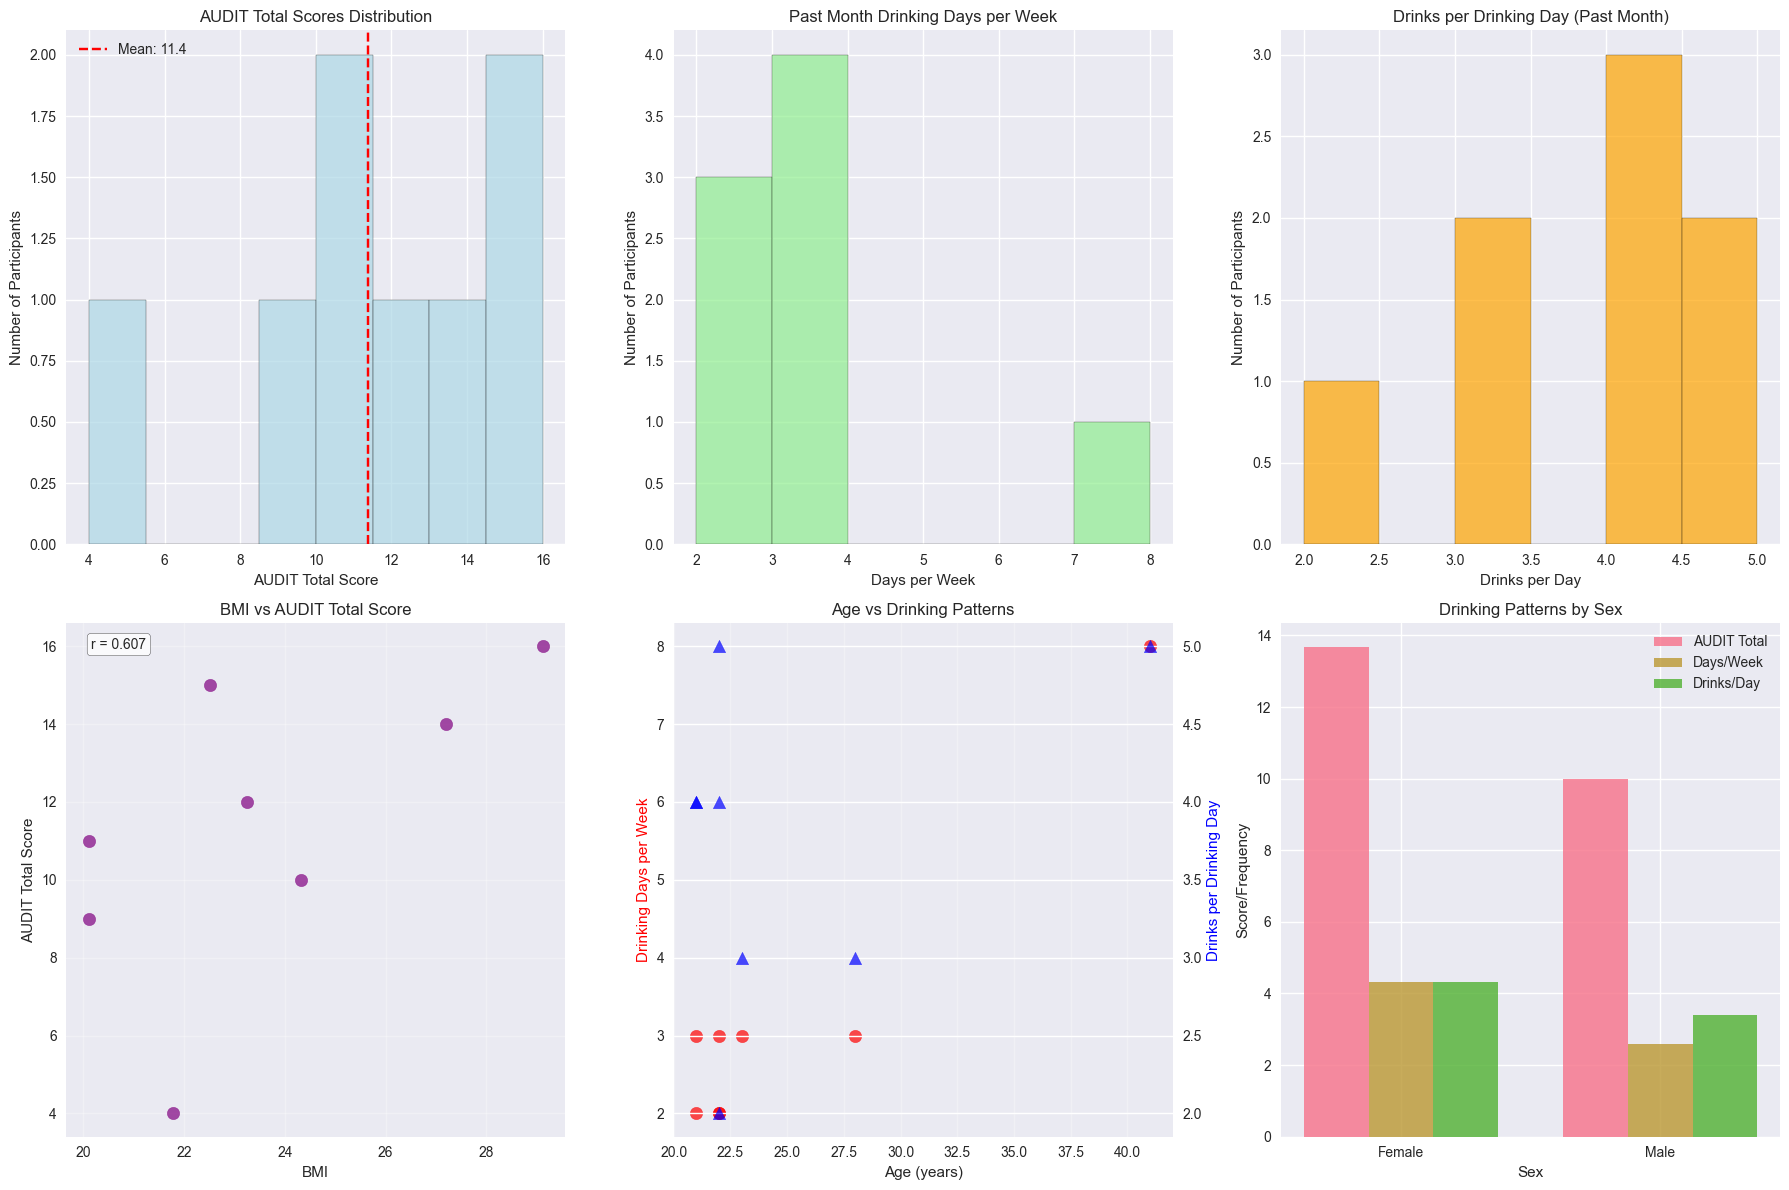

Baseline Participant Characteristics:
N = 8
Age: 25.0 ± 6.8 years
Sex (Female/Male): 3/5
BMI: 23.6 ± 3.2
AUDIT Total: 11.4 ± 3.9
Past month drinking days/week: 3.2 ± 2.0
Past month drinks/drinking day: 3.8 ± 1.0


In [7]:
# Baseline Drinking Characteristics
# Create a participant-level dataset (one row per participant)
participant_data = df.drop_duplicates('record_id')[['record_id', 'age', 'sex', 'bmi', 'audit_total', 
                                                     'pastmo_wkdd', 'pastmo_min_wkdd', 'pastmo_max_wkdd', 
                                                     'pastmo_dpdd', 'pastmo_binge_f', 'pastmo_binge_m']]

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. AUDIT scores
axes[0,0].hist(participant_data['audit_total'].dropna(), bins=8, color='lightblue', 
               alpha=0.7, edgecolor='black')
axes[0,0].set_title('AUDIT Total Scores Distribution')
axes[0,0].set_xlabel('AUDIT Total Score')
axes[0,0].set_ylabel('Number of Participants')
axes[0,0].axvline(participant_data['audit_total'].mean(), color='red', 
                  linestyle='--', label=f'Mean: {participant_data["audit_total"].mean():.1f}')
axes[0,0].legend()

# 2. Past month drinking days
axes[0,1].hist(participant_data['pastmo_wkdd'].dropna(), bins=6, color='lightgreen', 
               alpha=0.7, edgecolor='black')
axes[0,1].set_title('Past Month Drinking Days per Week')
axes[0,1].set_xlabel('Days per Week')
axes[0,1].set_ylabel('Number of Participants')

# 3. Past month drinks per drinking day
axes[0,2].hist(participant_data['pastmo_dpdd'].dropna(), bins=6, color='orange', 
               alpha=0.7, edgecolor='black')
axes[0,2].set_title('Drinks per Drinking Day (Past Month)')
axes[0,2].set_xlabel('Drinks per Day')
axes[0,2].set_ylabel('Number of Participants')

# 4. BMI vs AUDIT correlation
axes[1,0].scatter(participant_data['bmi'], participant_data['audit_total'], 
                  alpha=0.7, s=80, color='purple')
axes[1,0].set_title('BMI vs AUDIT Total Score')
axes[1,0].set_xlabel('BMI')
axes[1,0].set_ylabel('AUDIT Total Score')
axes[1,0].grid(True, alpha=0.3)

# Calculate and display correlation
bmi_audit_corr = participant_data[['bmi', 'audit_total']].corr().iloc[0,1]
axes[1,0].text(0.05, 0.95, f'r = {bmi_audit_corr:.3f}', transform=axes[1,0].transAxes, 
               bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# 5. Age vs drinking patterns
axes[1,1].scatter(participant_data['age'], participant_data['pastmo_wkdd'], 
                  alpha=0.7, s=80, color='red', label='Days/week')
ax_twin = axes[1,1].twinx()
ax_twin.scatter(participant_data['age'], participant_data['pastmo_dpdd'], 
                alpha=0.7, s=80, color='blue', marker='^', label='Drinks/day')
axes[1,1].set_title('Age vs Drinking Patterns')
axes[1,1].set_xlabel('Age (years)')
axes[1,1].set_ylabel('Drinking Days per Week', color='red')
ax_twin.set_ylabel('Drinks per Drinking Day', color='blue')
axes[1,1].grid(True, alpha=0.3)

# 6. Sex differences in drinking
sex_drinking = participant_data.groupby('sex')[['audit_total', 'pastmo_wkdd', 'pastmo_dpdd']].mean()
sex_labels = ['Female', 'Male']
x = np.arange(len(sex_labels))
width = 0.25

axes[1,2].bar(x - width, sex_drinking['audit_total'], width, label='AUDIT Total', alpha=0.8)
axes[1,2].bar(x, sex_drinking['pastmo_wkdd'], width, label='Days/Week', alpha=0.8)
axes[1,2].bar(x + width, sex_drinking['pastmo_dpdd'], width, label='Drinks/Day', alpha=0.8)

axes[1,2].set_title('Drinking Patterns by Sex')
axes[1,2].set_xlabel('Sex')
axes[1,2].set_ylabel('Score/Frequency')
axes[1,2].set_xticks(x)
axes[1,2].set_xticklabels(sex_labels)
axes[1,2].legend()

plt.tight_layout()
plt.show()

# Print baseline characteristics
print("Baseline Participant Characteristics:")
print(f"N = {len(participant_data)}")
print(f"Age: {participant_data['age'].mean():.1f} ± {participant_data['age'].std():.1f} years")
print(f"Sex (Female/Male): {(participant_data['sex'] == 0).sum()}/{(participant_data['sex'] == 1).sum()}")
print(f"BMI: {participant_data['bmi'].mean():.1f} ± {participant_data['bmi'].std():.1f}")
print(f"AUDIT Total: {participant_data['audit_total'].mean():.1f} ± {participant_data['audit_total'].std():.1f}")
print(f"Past month drinking days/week: {participant_data['pastmo_wkdd'].mean():.1f} ± {participant_data['pastmo_wkdd'].std():.1f}")
print(f"Past month drinks/drinking day: {participant_data['pastmo_dpdd'].mean():.1f} ± {participant_data['pastmo_dpdd'].std():.1f}")

# 6. Statistical Summary and Key Findings

In [8]:
# Statistical Summary and Key Findings
from scipy.stats import ttest_ind, pearsonr

print("=== STATISTICAL ANALYSIS SUMMARY ===\n")

# 1. Condition differences in key measures
print("1. CONDITION DIFFERENCES (Alcohol vs Control):")
print("-" * 50)

key_measures = ['brac', 'asatq_total', 'baes_stim', 'deq_feel', 'vas_hungry']
for measure in key_measures:
    alcohol_data = df[df['condition'] == 'alcohol'][measure].dropna()
    control_data = df[df['condition'] == 'control'][measure].dropna()
    
    if len(alcohol_data) > 0 and len(control_data) > 0:
        t_stat, p_value = ttest_ind(alcohol_data, control_data)
        
        print(f"{measure}:")
        print(f"  Alcohol: {alcohol_data.mean():.3f} ± {alcohol_data.std():.3f}")
        print(f"  Control: {control_data.mean():.3f} ± {control_data.std():.3f}")
        print(f"  t-test: t={t_stat:.3f}, p={p_value:.3f} {'***' if p_value < 0.001 else '**' if p_value < 0.01 else '*' if p_value < 0.05 else 'ns'}")
        print()

# 2. BRAC correlations with subjective measures
print("2. BRAC CORRELATIONS WITH SUBJECTIVE MEASURES:")
print("-" * 50)

correlation_measures = ['asatq_total', 'baes_stim', 'deq_feel', 'deq_like', 'vas_hungry']
for measure in correlation_measures:
    clean_data = df[['brac', measure]].dropna()
    if len(clean_data) > 5:
        r, p = pearsonr(clean_data['brac'], clean_data[measure])
        print(f"BRAC vs {measure}: r={r:.3f}, p={p:.3f} {'***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'}")

# 3. Time course analysis
print(f"\n3. TIME COURSE PATTERNS:")
print("-" * 50)

# Peak BRAC timing
alcohol_data = df[df['condition'] == 'alcohol']
peak_brac_per_participant = alcohol_data.groupby('record_id').apply(
    lambda x: x.loc[x['brac'].idxmax(), 'timepoint'] if len(x) > 0 else None
).dropna()

print(f"Peak BRAC typically occurs at timepoint: {peak_brac_per_participant.mode().iloc[0]:.0f}")
print(f"Peak BRAC timing range: {peak_brac_per_participant.min():.0f} - {peak_brac_per_participant.max():.0f}")

# 4. Individual differences
print(f"\n4. INDIVIDUAL DIFFERENCES:")
print("-" * 50)

# Peak BRAC by participant
peak_brac_values = alcohol_data.groupby('record_id')['brac'].max()
print(f"Peak BRAC range across participants: {peak_brac_values.min():.3f} - {peak_brac_values.max():.3f}")
print(f"Peak BRAC variability (CV): {(peak_brac_values.std()/peak_brac_values.mean())*100:.1f}%")

# 5. Key visualizable statistics
print(f"\n5. KEY VISUALIZABLE STATISTICS:")
print("-" * 50)
print("✓ Study Design: 8 participants, 2 conditions (alcohol/control), 7 timepoints")
print("✓ BRAC Trajectories: Clear alcohol vs control differences")
print("✓ Psychological Measures: 15+ scales tracking mood, craving, drug effects")
print("✓ Appetite Measures: VAS scales for hunger, satiation, fullness")
print("✓ Individual Differences: Varied responses to alcohol")
print("✓ Baseline Characteristics: Age, BMI, drinking history (AUDIT)")
print("✓ Time Course: 7 measurement points over ~3 hours")
print("✓ Correlations: BRAC with subjective measures")
print("✓ Sex Differences: 3 female, 5 male participants")

# Summary table of all measures
summary_stats = df.groupby('condition').agg({
    'brac': ['mean', 'std', 'max'],
    'asatq_total': ['mean', 'std'],
    'baes_stim': ['mean', 'std'],
    'vas_hungry': ['mean', 'std'],
    'age': ['mean', 'std'],
    'bmi': ['mean', 'std']
}).round(3)

print(f"\n6. SUMMARY STATISTICS TABLE:")
print("-" * 50)
print(summary_stats)

=== STATISTICAL ANALYSIS SUMMARY ===

1. CONDITION DIFFERENCES (Alcohol vs Control):
--------------------------------------------------
brac:
  Alcohol: 0.048 ± 0.026
  Control: 0.014 ± 0.011
  t-test: t=6.653, p=0.000 ***

asatq_total:
  Alcohol: 92.257 ± 40.662
  Control: 61.643 ± 31.972
  t-test: t=3.257, p=0.002 **

baes_stim:
  Alcohol: 13.743 ± 7.261
  Control: 6.214 ± 6.951
  t-test: t=4.167, p=0.000 ***

deq_feel:
  Alcohol: 55.371 ± 18.281
  Control: 45.607 ± 27.158
  t-test: t=1.701, p=0.094 ns

vas_hungry:
  Alcohol: 49.171 ± 27.326
  Control: 76.786 ± 10.178
  t-test: t=-5.067, p=0.000 ***

2. BRAC CORRELATIONS WITH SUBJECTIVE MEASURES:
--------------------------------------------------
BRAC vs asatq_total: r=0.115, p=0.369 ns
BRAC vs baes_stim: r=0.216, p=0.090 ns
BRAC vs deq_feel: r=0.448, p=0.000 ***
BRAC vs deq_like: r=-0.070, p=0.588 ns
BRAC vs vas_hungry: r=-0.393, p=0.001 **

3. TIME COURSE PATTERNS:
--------------------------------------------------
Peak BRAC typica